In [2]:
import os

print("Current directory:", os.getcwd())
print("Available files:", os.listdir())

Current directory: /drive
Available files: ['Untitled.ipynb', 'Untitled1.ipynb', 'data', 'notebooks', 'README.md']


In [5]:
import os

print(os.listdir("/drive/data"))

['bar.vl.json', 'Museums_in_DC.geojson', 'audio.wav', 'iris.csv', 'matplotlib.png', 'marie.png', 'fasta-example.fasta']


In [7]:
import os

for root, dirs, files in os.walk("/drive"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

/drive/pakistan-household-income-consumption-hies-2024-25.csv
/drive/data/iris.csv


In [10]:
import pandas as pd

df = pd.read_csv(
    "/drive/pakistan-household-income-consumption-hies-2024-25.csv"
)

display(df.head())

,geography_name,indicator_label,reference_period,dimension,value,unit,source_id,caveat
0,Pakistan,Average household size (HIES),HIES 2018–19,NaN,6.24,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
1,Pakistan,Average household size (HIES),HIES 2024–25,NaN,5.98,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
2,Balochistan,Average household size (HIES),HIES 2024–25,NaN,7.08,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
3,Khyber Pakhtunkhwa,Average household size (HIES),HIES 2024–25,NaN,6.83,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
4,Punjab,Average household size (HIES),HIES 2024–25,NaN,5.77,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."


In [11]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (108, 8)

Column Names:
['geography_name', 'indicator_label', 'reference_period', 'dimension', 'value', 'unit', 'source_id', 'caveat']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   geography_name    108 non-null    str    
 1   indicator_label   108 non-null    str    
 2   reference_period  108 non-null    str    
 3   dimension         86 non-null     str    
 4   value             108 non-null    float64
 5   unit              108 non-null    str    
 6   source_id         108 non-null    str    
 7   caveat            108 non-null    str    
dtypes: float64(1), str(7)
memory usage: 3.9 KB


In [12]:
print(df.isnull().sum())

geography_name       0
indicator_label      0
reference_period     0
dimension           22
value                0
unit                 0
source_id            0
caveat               0
dtype: int64


In [13]:
# Display rows where dimension is missing

missing_dimension = df[df["dimension"].isnull()]

display(missing_dimension)

,geography_name,indicator_label,reference_period,dimension,value,unit,source_id,caveat
0,Pakistan,Average household size (HIES),HIES 2018–19,NaN,6.24,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
1,Pakistan,Average household size (HIES),HIES 2024–25,NaN,5.98,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
2,Balochistan,Average household size (HIES),HIES 2024–25,NaN,7.08,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
3,Khyber Pakhtunkhwa,Average household size (HIES),HIES 2024–25,NaN,6.83,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
4,Punjab,Average household size (HIES),HIES 2024–25,NaN,5.77,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
5,Rural,Average household size (HIES),HIES 2018–19,NaN,6.40,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
6,Rural,Average household size (HIES),HIES 2024–25,NaN,6.18,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
7,Sindh,Average household size (HIES),HIES 2024–25,NaN,5.70,persons_per_household,PBS_HIES_ECONOMIC_REPORT,"Survey estimate, not a census enumeration."
8,Urban,Average household size (HIES),HIES 2018–19,NaN,5.97,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...
9,Urban,Average household size (HIES),HIES 2024–25,NaN,5.69,persons_per_household,PBS_HIES_ECONOMIC_REPORT,Do not substitute for Census 2023 average hous...


In [14]:
# Replace missing categorical values
df["dimension"] = df["dimension"].fillna("Not Applicable")

# Verify missing values
print(df.isnull().sum())

geography_name      0
indicator_label     0
reference_period    0
dimension           0
value               0
unit                0
source_id           0
caveat              0
dtype: int64


In [15]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDimension categories:")
print(df["dimension"].value_counts())

Missing values after cleaning:
geography_name      0
indicator_label     0
reference_period    0
dimension           0
value               0
unit                0
source_id           0
caveat              0
dtype: int64

Dimension categories:
dimension
Not Applicable                                                      22
income_source=Crop production                                        6
income_source=Domestic remittances                                   6
income_source=Foreign remittances                                    6
income_source=Gifts and assistance including BISP transfers          6
income_source=Livestock                                              6
income_source=Other non-agricultural activities                      6
income_source=Other sources                                          6
income_source=Owner-occupied housing services                        6
income_source=Property excluding owner-occupied housing services     6
income_source=Social insurance benefi

In [16]:
df.to_csv(
    "/drive/pakistan_hies_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:
df.dtypes

geography_name          str
indicator_label         str
reference_period        str
dimension               str
value               float64
unit                    str
source_id               str
caveat                  str
dtype: object

In [18]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [19]:
df.describe()

,value
count,108.000000
mean,17112.137593
std,30900.209421
min,0.070000
25%,3.792500
50%,7.220000
75%,30583.250000
max,139317.000000


In [20]:
categorical_columns = [
    "geography_name",
    "indicator_label",
    "reference_period",
    "unit"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 geography_name
geography_name
Pakistan              48
Rural                 28
Urban                 28
Balochistan            1
Khyber Pakhtunkhwa     1
Punjab                 1
Sindh                  1
Name: count, dtype: int64

 indicator_label
indicator_label
Share of monthly household income by source                      66
Average household size (HIES)                                    10
Average monthly household consumption by consumption quintile    10
Average monthly household income by consumption quintile         10
Average monthly household consumption expenditure                 6
Average monthly household income                                  6
Name: count, dtype: int64

 reference_period
reference_period
HIES 2024–25    56
HIES 2018–19    52
Name: count, dtype: int64

 unit
unit
percent_of_household_income    66
PKR_per_household_per_month    32
persons_per_household          10
Name: count, dtype: int64


In [21]:
df["indicator_label"].value_counts()

indicator_label
Share of monthly household income by source                      66
Average household size (HIES)                                    10
Average monthly household consumption by consumption quintile    10
Average monthly household income by consumption quintile         10
Average monthly household consumption expenditure                 6
Average monthly household income                                  6
Name: count, dtype: int64

In [22]:
print(df["geography_name"].value_counts())

geography_name
Pakistan              48
Rural                 28
Urban                 28
Balochistan            1
Khyber Pakhtunkhwa     1
Punjab                 1
Sindh                  1
Name: count, dtype: int64


In [23]:
print(df["reference_period"].value_counts())

reference_period
HIES 2024–25    56
HIES 2018–19    52
Name: count, dtype: int64


In [24]:
print(df["unit"].value_counts())

unit
percent_of_household_income    66
PKR_per_household_per_month    32
persons_per_household          10
Name: count, dtype: int64


In [25]:
# Filter national household income data

income_data = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] == "Average monthly household income")
]

# Display selected records
display(income_data[
    ["geography_name", "reference_period", "value", "unit"]
])

,geography_name,reference_period,value,unit
26,Pakistan,HIES 2018–19,41545.0,PKR_per_household_per_month
32,Pakistan,HIES 2024–25,82179.0,PKR_per_household_per_month


In [26]:
# Arrange income data by survey period

income_comparison = income_data[
    ["reference_period", "value"]
].sort_values("reference_period")

display(income_comparison)

,reference_period,value
26,HIES 2018–19,41545.0
32,HIES 2024–25,82179.0


In [27]:
income_2018 = income_comparison.iloc[0]["value"]
income_2024 = income_comparison.iloc[1]["value"]

percentage_growth = (
    (income_2024 - income_2018) / income_2018
) * 100

print("Income in 2018-19:", income_2018)
print("Income in 2024-25:", income_2024)

print("Percentage growth:", round(percentage_growth, 2), "%")

Income in 2018-19: 41545.0
Income in 2024-25: 82179.0
Percentage growth: 97.81 %


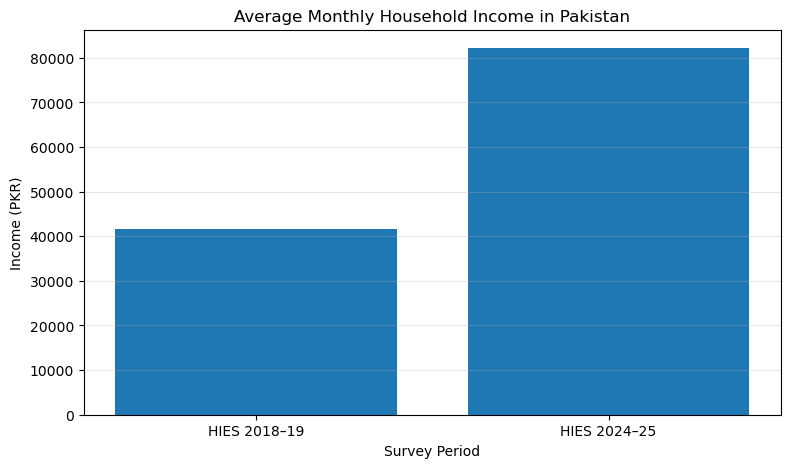

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    income_comparison["reference_period"],
    income_comparison["value"]
)

plt.title("Average Monthly Household Income in Pakistan")
plt.xlabel("Survey Period")
plt.ylabel("Income (PKR)")
plt.grid(axis="y", alpha=0.3)

plt.show()

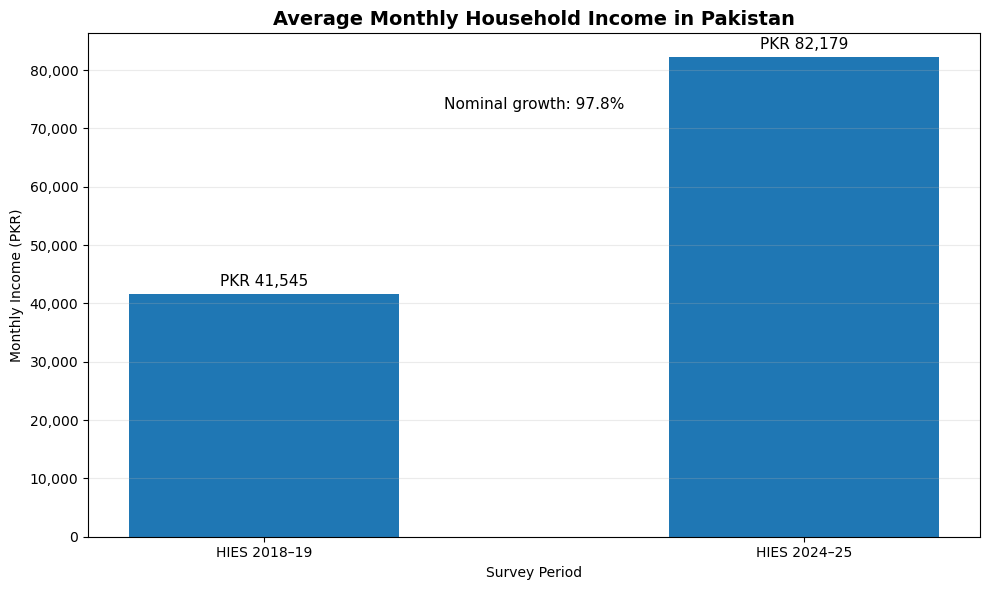

In [29]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 6))

bars = plt.bar(
    income_comparison["reference_period"],
    income_comparison["value"],
    width=0.5
)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1500,
        f"PKR {height:,.0f}",
        ha="center",
        fontsize=11
    )

plt.title(
    "Average Monthly Household Income in Pakistan",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Survey Period")
plt.ylabel("Monthly Income (PKR)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.annotate(
    f"Nominal growth: {percentage_growth:.1f}%",
    xy=(0.5, 0.85),
    xycoords="axes fraction",
    ha="center",
    fontsize=11
)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [30]:
rural_urban_income = df[
    (df["geography_name"].isin(["Rural", "Urban"])) &
    (df["indicator_label"] == "Average monthly household income")
]

display(
    rural_urban_income[
        ["geography_name", "reference_period", "value"]
    ].sort_values(["geography_name", "reference_period"])
)

,geography_name,reference_period,value
38,Rural,HIES 2018–19,34520.0
39,Rural,HIES 2024–25,72157.0
40,Urban,HIES 2018–19,53010.0
41,Urban,HIES 2024–25,96767.0


In [31]:
# Calculate rural and urban income growth

for area in ["Rural", "Urban"]:

    area_data = rural_urban_income[
        rural_urban_income["geography_name"] == area
    ].sort_values("reference_period")

    old_income = area_data.iloc[0]["value"]
    new_income = area_data.iloc[1]["value"]

    growth = ((new_income - old_income) / old_income) * 100

    print(f"{area} income growth: {growth:.2f}%")

Rural income growth: 109.03%
Urban income growth: 82.54%


In [32]:
# Calculate urban-rural income gap

income_pivot = rural_urban_income.pivot(
    index="reference_period",
    columns="geography_name",
    values="value"
)

income_pivot["Income_Gap"] = (
    income_pivot["Urban"] - income_pivot["Rural"]
)

display(income_pivot)

geography_name,Rural,Urban,Income_Gap
reference_period,,,
HIES 2018–19,34520.0,53010.0,18490.0
HIES 2024–25,72157.0,96767.0,24610.0


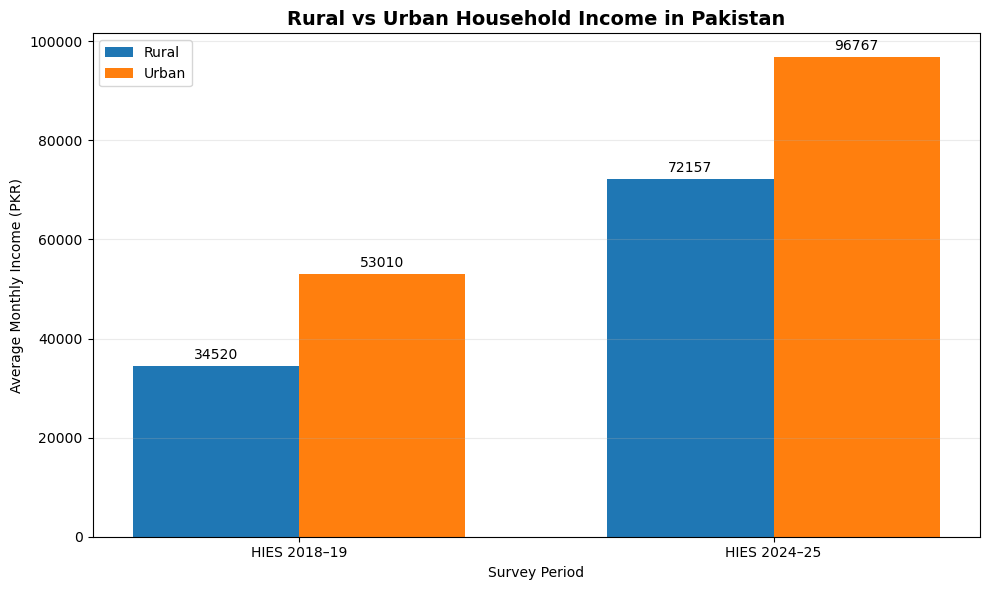

In [33]:
import matplotlib.pyplot as plt
import numpy as np

income_pivot = rural_urban_income.pivot(
    index="reference_period",
    columns="geography_name",
    values="value"
)

periods = income_pivot.index
x = np.arange(len(periods))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

rural_bars = ax.bar(
    x - width/2,
    income_pivot["Rural"],
    width,
    label="Rural"
)

urban_bars = ax.bar(
    x + width/2,
    income_pivot["Urban"],
    width,
    label="Urban"
)

ax.bar_label(rural_bars, fmt="%.0f", padding=3)
ax.bar_label(urban_bars, fmt="%.0f", padding=3)

ax.set_title(
    "Rural vs Urban Household Income in Pakistan",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Survey Period")
ax.set_ylabel("Average Monthly Income (PKR)")
ax.set_xticks(x)
ax.set_xticklabels(periods)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [34]:
# Filter provincial household income

provincial_income = df[
    (df["geography_name"].isin([
        "Punjab",
        "Sindh",
        "Khyber Pakhtunkhwa",
        "Balochistan"
    ])) &
    (df["indicator_label"] == "Average monthly household income")
]

# Display results

display(
    provincial_income[
        ["geography_name", "reference_period", "value"]
    ].sort_values(["reference_period", "value"], ascending=[True, False])
)

,geography_name,reference_period,value


In [35]:
print(df["geography_name"].unique())

<StringArray>
[          'Pakistan',        'Balochistan', 'Khyber Pakhtunkhwa',
             'Punjab',              'Rural',              'Sindh',
              'Urban']
Length: 7, dtype: str


In [36]:
income_check = df[
    df["indicator_label"] == "Average monthly household income"
]

display(
    income_check[
        ["geography_name", "reference_period", "value"]
    ]
)

,geography_name,reference_period,value
26,Pakistan,HIES 2018–19,41545.0
32,Pakistan,HIES 2024–25,82179.0
38,Rural,HIES 2018–19,34520.0
39,Rural,HIES 2024–25,72157.0
40,Urban,HIES 2018–19,53010.0
41,Urban,HIES 2024–25,96767.0


In [37]:
provincial_size = df[
    (df["geography_name"].isin([
        "Punjab",
        "Sindh",
        "Khyber Pakhtunkhwa",
        "Balochistan"
    ])) &
    (df["indicator_label"] == "Average household size (HIES)")
]

display(
    provincial_size[
        ["geography_name", "reference_period", "value"]
    ].sort_values(["reference_period", "value"], ascending=[True, False])
)

,geography_name,reference_period,value
2,Balochistan,HIES 2024–25,7.08
3,Khyber Pakhtunkhwa,HIES 2024–25,6.83
4,Punjab,HIES 2024–25,5.77
7,Sindh,HIES 2024–25,5.70


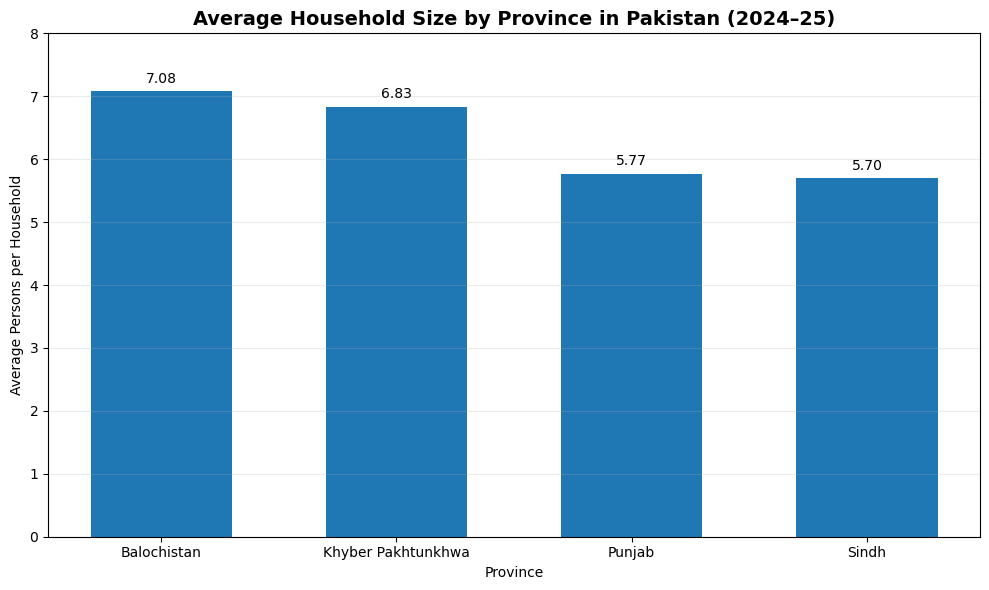

In [38]:
import matplotlib.pyplot as plt

# Sort provinces by household size
provincial_size_sorted = provincial_size.sort_values(
    "value",
    ascending=False
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    provincial_size_sorted["geography_name"],
    provincial_size_sorted["value"],
    width=0.6
)

# Add data labels
plt.bar_label(
    bars,
    fmt="%.2f",
    padding=4
)

plt.title(
    "Average Household Size by Province in Pakistan (2024–25)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Province")
plt.ylabel("Average Persons per Household")

plt.ylim(0, 8)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [39]:
income_sources = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] ==
     "Share of monthly household income by source") &
    (df["reference_period"] == "HIES 2024–25")
]

display(
    income_sources[
        ["dimension", "value", "unit"]
    ].sort_values("value", ascending=False)
)

,dimension,value,unit
63,income_source=Wages and salaries,42.00,percent_of_household_income
58,income_source=Other non-agricultural activities,16.25,percent_of_household_income
55,income_source=Foreign remittances,7.77,percent_of_household_income
57,income_source=Livestock,7.07,percent_of_household_income
53,income_source=Crop production,6.89,percent_of_household_income
60,income_source=Owner-occupied housing services,5.59,percent_of_household_income
56,income_source=Gifts and assistance including B...,4.57,percent_of_household_income
62,income_source=Social insurance benefits includ...,3.80,percent_of_household_income
54,income_source=Domestic remittances,3.77,percent_of_household_income
61,income_source=Property excluding owner-occupie...,1.91,percent_of_household_income


In [40]:
total_percentage = income_sources["value"].sum()

print("Total income share:", round(total_percentage, 2), "%")

Total income share: 100.0 %


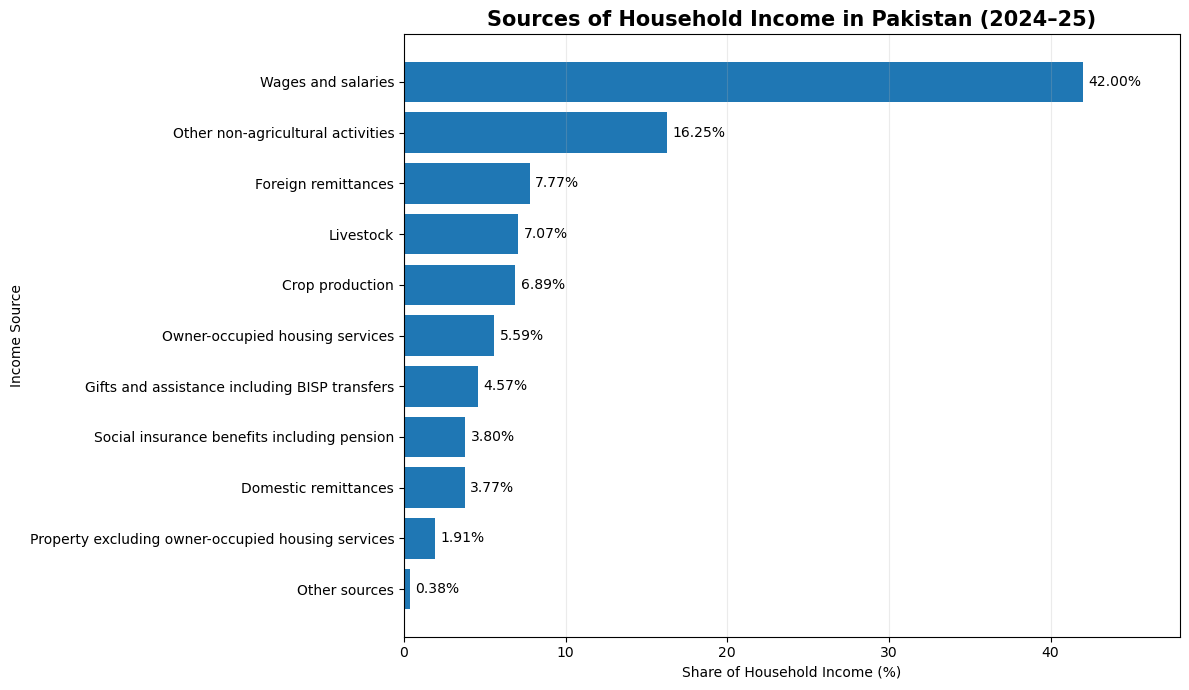

In [41]:
import matplotlib.pyplot as plt

# Clean income source labels
income_sources = income_sources.copy()

income_sources["income_source"] = (
    income_sources["dimension"]
    .str.replace("income_source=", "", regex=False)
)

# Sort by percentage
income_sources = income_sources.sort_values(
    "value", ascending=True
)

# Create chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    income_sources["income_source"],
    income_sources["value"]
)

# Add percentage labels
plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

plt.title(
    "Sources of Household Income in Pakistan (2024–25)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Share of Household Income (%)")
plt.ylabel("Income Source")

plt.xlim(0, 48)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [42]:
quintile_data = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] ==
     "Average monthly household consumption by consumption quintile") &
    (df["reference_period"] == "HIES 2024–25")
]

display(
    quintile_data[
        ["dimension", "value", "unit"]
    ].sort_values("dimension")
)

,dimension,value,unit
17,consumption_quintile=Q1,39998.0,PKR_per_household_per_month
18,consumption_quintile=Q2,53283.0,PKR_per_household_per_month
19,consumption_quintile=Q3,62880.0,PKR_per_household_per_month
20,consumption_quintile=Q4,77302.0,PKR_per_household_per_month
21,consumption_quintile=Q5,134684.0,PKR_per_household_per_month


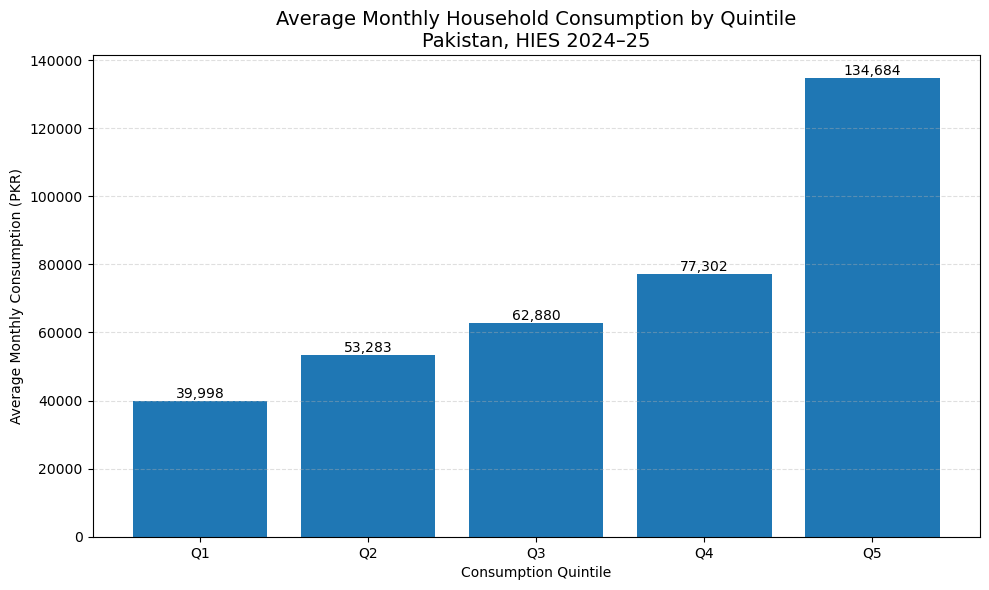

In [43]:
import matplotlib.pyplot as plt

# Prepare data
quintile_data = quintile_data.copy()
quintile_data["quintile"] = quintile_data["dimension"].str.extract(r"(Q\d)")

quintile_data = quintile_data.sort_values("quintile")

# Create chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    quintile_data["quintile"],
    quintile_data["value"]
)

plt.title(
    "Average Monthly Household Consumption by Quintile\nPakistan, HIES 2024–25",
    fontsize=14
)
plt.xlabel("Consumption Quintile")
plt.ylabel("Average Monthly Consumption (PKR)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [44]:
income_quintile = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] ==
     "Average monthly household income by consumption quintile") &
    (df["reference_period"] == "HIES 2024–25")
]

display(
    income_quintile[
        ["dimension", "value", "unit"]
    ].sort_values("dimension")
)

,dimension,value,unit
33,consumption_quintile=Q1,41851.0,PKR_per_household_per_month
34,consumption_quintile=Q2,55138.0,PKR_per_household_per_month
35,consumption_quintile=Q3,65741.0,PKR_per_household_per_month
36,consumption_quintile=Q4,80387.0,PKR_per_household_per_month
37,consumption_quintile=Q5,139317.0,PKR_per_household_per_month


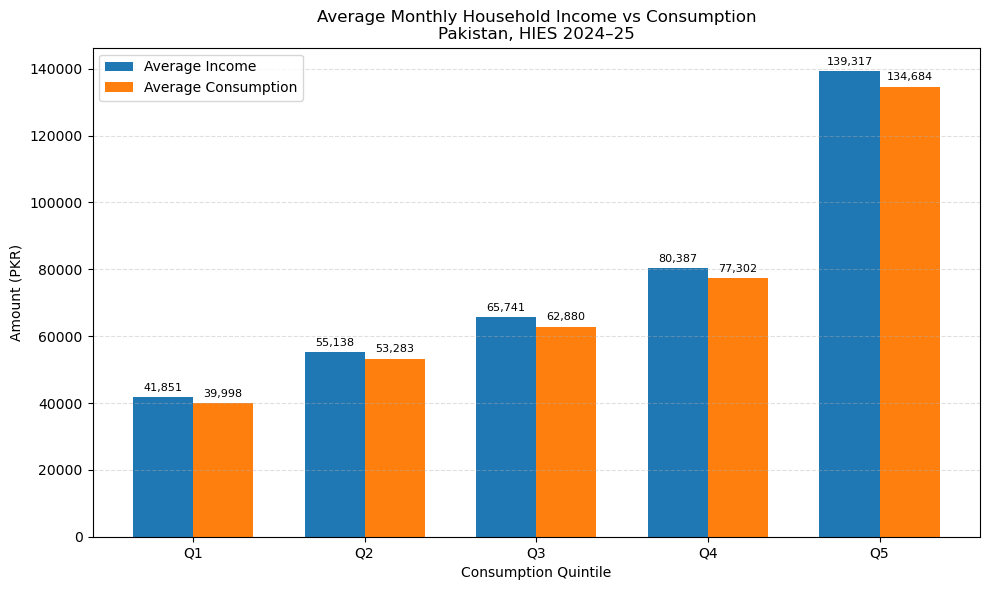

In [45]:
import matplotlib.pyplot as plt
import numpy as np

quintiles = ["Q1", "Q2", "Q3", "Q4", "Q5"]

income = [41851, 55138, 65741, 80387, 139317]

consumption = [39998, 53283, 62880, 77302, 134684]

x = np.arange(len(quintiles))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2,
    income,
    width,
    label="Average Income"
)

bars2 = plt.bar(
    x + width/2,
    consumption,
    width,
    label="Average Consumption"
)

plt.title(
    "Average Monthly Household Income vs Consumption\nPakistan, HIES 2024–25"
)

plt.xlabel("Consumption Quintile")
plt.ylabel("Amount (PKR)")
plt.xticks(x, quintiles)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.bar_label(
    bars1,
    labels=[f"{v:,}" for v in income],
    padding=3,
    fontsize=8
)

plt.bar_label(
    bars2,
    labels=[f"{v:,}" for v in consumption],
    padding=3,
    fontsize=8
)

plt.tight_layout()
plt.show()

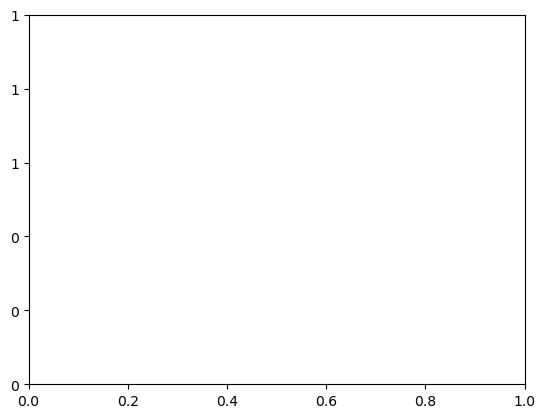

In [46]:
import matplotlib.ticker as ticker

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

In [47]:
consumption_data = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] ==
     "Average monthly household consumption expenditure") &
    (df["reference_period"] == "HIES 2024–25")
]

display(
    consumption_data[
        ["dimension", "value", "unit"]
    ].sort_values("value", ascending=False)
)

,dimension,value,unit
16,Not Applicable,79150.0,PKR_per_household_per_month


In [48]:
consumption_trend = df[
    (df["geography_name"] == "Pakistan") &
    (df["indicator_label"] ==
     "Average monthly household consumption expenditure")
]

display(
    consumption_trend[
        ["reference_period", "value", "unit"]
    ].sort_values("reference_period")
)

,reference_period,value,unit
10,HIES 2018–19,37159.0,PKR_per_household_per_month
16,HIES 2024–25,79150.0,PKR_per_household_per_month


In [49]:
old_value = 37159
new_value = 79150

absolute_increase = new_value - old_value

percentage_growth = (
    (new_value - old_value) / old_value
) * 100

print("Absolute Increase:", absolute_increase)
print("Percentage Growth:", round(percentage_growth, 2), "%")

Absolute Increase: 41991
Percentage Growth: 113.0 %


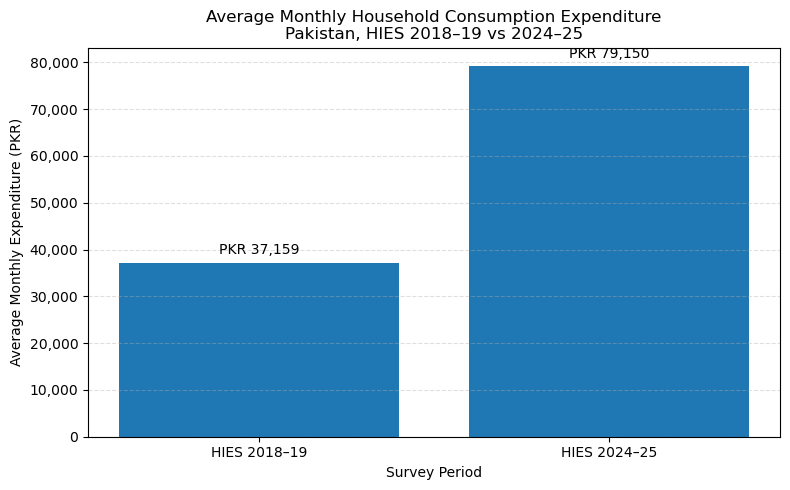

In [50]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

periods = ["HIES 2018–19", "HIES 2024–25"]
consumption = [37159, 79150]

plt.figure(figsize=(8, 5))

bars = plt.bar(periods, consumption)

plt.title(
    "Average Monthly Household Consumption Expenditure\nPakistan, HIES 2018–19 vs 2024–25"
)

plt.xlabel("Survey Period")
plt.ylabel("Average Monthly Expenditure (PKR)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

plt.bar_label(
    bars,
    labels=[f"PKR {v:,}" for v in consumption],
    padding=4
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()